<a href="https://colab.research.google.com/github/perumalla1116/MachineLearning/blob/main/SVM_249.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q ucimlrepo

from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

heart_disease = fetch_ucirepo(id=45)

X = heart_disease.data.features.copy()
y = heart_disease.data.targets.copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Features shape: (303, 13)
Target shape: (303, 1)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


,num
0,0
1,2
2,1
3,0
4,0


In [2]:
print("Dataset information:")
X.info()

print("\nMissing values per feature:")
print(X.isnull().sum())

print("\nTotal missing values:", X.isnull().sum().sum())
print("Duplicate feature rows:", X.duplicated().sum())
print("Duplicate column names:", X.columns.duplicated().sum())

print("\nTarget distribution:")
print(y['num'].value_counts().sort_index())

print("\nStatistical summary:")
display(X.describe().T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
dtypes: float64(3), int64(10)
memory usage: 30.9 KB

Missing values per feature:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
dtype: int64

Total missin

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [3]:
for col in X.columns:
    X[col] = X[col].fillna(X[col].median())

y = y['num'].apply(lambda value: 0 if value == 0 else 1)

print("Missing values remaining:", X.isnull().sum().sum())
print("Target missing values:", y.isnull().sum())
print("\nTarget distribution:")
print(y.value_counts().sort_index())
print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Missing values remaining: 0
Target missing values: 0

Target distribution:
num
0    164
1    139
Name: count, dtype: int64

Feature shape: (303, 13)
Target shape: (303,)


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Training features: (242, 13)
Testing features: (61, 13)

Training target distribution:
num
0    131
1    111
Name: count, dtype: int64

Testing target distribution:
num
0    33
1    28
Name: count, dtype: int64


In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

print("\nMean of first 5 scaled training features:")
print(X_train_scaled.mean(axis=0)[:5])

Scaled training shape: (242, 13)
Scaled testing shape: (61, 13)

Mean of first 5 scaled training features:
[-1.83507938e-16  1.02764445e-16  1.80755319e-16 -3.85366670e-16
  1.46806350e-16]


In [6]:
from sklearn.svm import SVC

svm_linear = SVC(kernel='linear')

svm_linear.fit(X_train_scaled, y_train)

y_pred_linear = svm_linear.predict(X_test_scaled)

print("First 20 predictions:")
print(y_pred_linear[:20])

First 20 predictions:
[0 1 0 0 1 0 0 0 1 0 1 0 0 1 1 1 1 0 1 1]


In [7]:
from sklearn.metrics import accuracy_score

accuracy_linear = accuracy_score(y_test, y_pred_linear)

print("Linear SVM Accuracy:", accuracy_linear)
print("Accuracy Percentage:", accuracy_linear * 100, "%")

Linear SVM Accuracy: 0.8524590163934426
Accuracy Percentage: 85.24590163934425 %


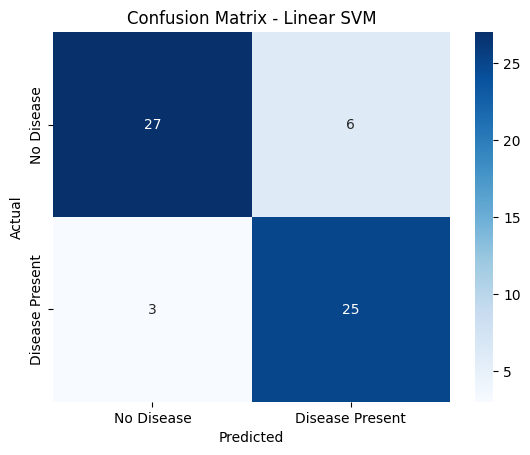

                 precision    recall  f1-score   support

     No Disease       0.90      0.82      0.86        33
Disease Present       0.81      0.89      0.85        28

       accuracy                           0.85        61
      macro avg       0.85      0.86      0.85        61
   weighted avg       0.86      0.85      0.85        61



In [8]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

cm_linear = confusion_matrix(y_test, y_pred_linear)

sns.heatmap(
    cm_linear,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Disease', 'Disease Present'],
    yticklabels=['No Disease', 'Disease Present']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Linear SVM')
plt.show()

print(classification_report(
    y_test,
    y_pred_linear,
    target_names=['No Disease', 'Disease Present']
))

In [9]:
svm_rbf = SVC(kernel='rbf')

svm_rbf.fit(X_train_scaled, y_train)

y_pred_rbf = svm_rbf.predict(X_test_scaled)

print("First 20 predictions:")
print(y_pred_rbf[:20])

First 20 predictions:
[0 1 0 0 1 0 0 0 1 0 1 0 0 1 1 1 1 0 1 1]


In [10]:
from sklearn.metrics import accuracy_score

accuracy_rbf = accuracy_score(y_test, y_pred_rbf)

print("Nonlinear SVM (RBF) Accuracy:", accuracy_rbf)
print("Accuracy Percentage:", accuracy_rbf * 100, "%")

Nonlinear SVM (RBF) Accuracy: 0.8524590163934426
Accuracy Percentage: 85.24590163934425 %


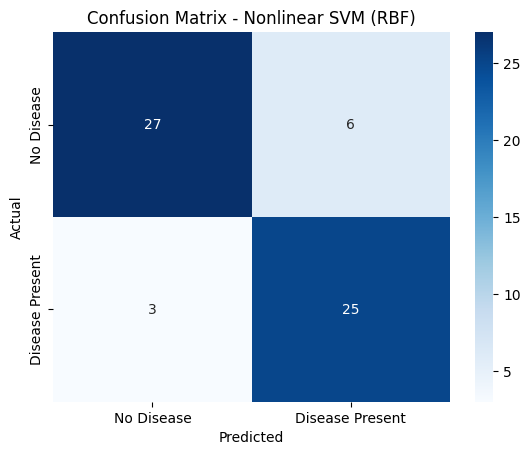

                 precision    recall  f1-score   support

     No Disease       0.90      0.82      0.86        33
Disease Present       0.81      0.89      0.85        28

       accuracy                           0.85        61
      macro avg       0.85      0.86      0.85        61
   weighted avg       0.86      0.85      0.85        61



In [11]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

cm_rbf = confusion_matrix(y_test, y_pred_rbf)

sns.heatmap(
    cm_rbf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Disease', 'Disease Present'],
    yticklabels=['No Disease', 'Disease Present']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Nonlinear SVM (RBF)')
plt.show()

print(classification_report(
    y_test,
    y_pred_rbf,
    target_names=['No Disease', 'Disease Present']
))

In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision (Disease Present)',
        'Recall (Disease Present)',
        'F1-score (Disease Present)'
    ],
    'Linear SVM': [
        accuracy_score(y_test, y_pred_linear),
        precision_score(y_test, y_pred_linear),
        recall_score(y_test, y_pred_linear),
        f1_score(y_test, y_pred_linear)
    ],
    'Nonlinear SVM (RBF)': [
        accuracy_score(y_test, y_pred_rbf),
        precision_score(y_test, y_pred_rbf),
        recall_score(y_test, y_pred_rbf),
        f1_score(y_test, y_pred_rbf)
    ]
})

display(results.round(4))

,Metric,Linear SVM,Nonlinear SVM (RBF)
0,Accuracy,0.8525,0.8525
1,Precision (Disease Present),0.8065,0.8065
2,Recall (Disease Present),0.8929,0.8929
3,F1-score (Disease Present),0.8475,0.8475
